#### inicialização

In [20]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib

print('Matplotlib', matplotlib.__version__)


Matplotlib 3.11.2


In [21]:
df_24_1 = pd.read_csv('ca-2024-01.csv', sep=';', decimal=',')
df_24_2 = pd.read_csv('ca-2024-02.csv', sep=';', decimal=',')
df_25_1 = pd.read_csv('ca-2025-01.csv', sep=';', decimal=',')
df_25_2 = pd.read_csv('ca-2025-02.csv', sep=';', decimal=',')


#### Nº 1
    contrução da base


In [210]:
df = pd.concat([df_24_1, df_24_2,
 df_25_1, df_25_2],
 ignore_index=True)

print(df.shape) 
display(df.head())


(1712267, 16)


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA,01/01/2024,5.68,NaN,R$ / litro,VIBRA
1,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA ADITIVADA,01/01/2024,5.68,NaN,R$ / litro,VIBRA
2,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,DIESEL S10,01/01/2024,5.93,NaN,R$ / litro,VIBRA
3,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,ETANOL,01/01/2024,3.99,NaN,R$ / litro,VIBRA
4,NE,AL,ARAPIRACA,AUTO POSTO SAO FRANCISCO LTDA,12.706.529/0001-04,RUA SAO FRANCISCO,274,NaN,CENTRO,57300-080,GASOLINA,01/01/2024,5.48,NaN,R$ / litro,VIBRA


In [23]:
df.columns

Index(['Regiao - Sigla', 'Estado - Sigla', 'Municipio', 'Revenda',
       'CNPJ da Revenda', 'Nome da Rua', 'Numero Rua', 'Complemento', 'Bairro',
       'Cep', 'Produto', 'Data da Coleta', 'Valor de Venda', 'Valor de Compra',
       'Unidade de Medida', 'Bandeira'],
      dtype='str')

In [ ]:
df['Municipio'].unique()
#df.loc[df['Estado - Sigla'] == 'RJ', 'Municipio'].unique()

<StringArray>
[      'CAMPOS DOS GOYTACAZES',                 'NOVA IGUACU',
          'SAO JOAO DE MERITI',               'VOLTA REDONDA',
                   'CABO FRIO',              'ANGRA DOS REIS',
              'BARRA DO PIRAI',                   'ITAPERUNA',
                     'NITEROI',                  'RIO BONITO',
              'RIO DE JANEIRO',      'SANTO ANTONIO DE PADUA',
                 'SAO GONCALO',                 'TERESOPOLIS',
                 'BARRA MANSA',                    'ITABORAI',
               'NOVA FRIBURGO',                  'PETROPOLIS',
                     'ITAGUAI',                    'ARARUAMA',
                   'SAQUAREMA',                   'TRES RIOS',
             'DUQUE DE CAXIAS',                    'SAPUCAIA',
                     'VALENCA',                       'MACAE',
                      'MARICA',                   'NILOPOLIS',
 'SAO FRANCISCO DE ITABAPOANA',                'BELFORD ROXO',
                        'MAGE',          

#### Nº2
    Gasolina C no Rio de Janeiro

In [211]:
df_rj = df.loc[(df['Estado - Sigla'] == 'RJ') & (df['Produto'] == 'GASOLINA')]
df_rj['Municipio'].unique()



<StringArray>
[      'CAMPOS DOS GOYTACAZES',                 'NOVA IGUACU',
          'SAO JOAO DE MERITI',               'VOLTA REDONDA',
                   'CABO FRIO',              'ANGRA DOS REIS',
              'BARRA DO PIRAI',                   'ITAPERUNA',
                     'NITEROI',                  'RIO BONITO',
              'RIO DE JANEIRO',      'SANTO ANTONIO DE PADUA',
                 'SAO GONCALO',                 'TERESOPOLIS',
                 'BARRA MANSA',                    'ITABORAI',
               'NOVA FRIBURGO',                  'PETROPOLIS',
                     'ITAGUAI',                    'ARARUAMA',
                   'SAQUAREMA',                   'TRES RIOS',
             'DUQUE DE CAXIAS',                    'SAPUCAIA',
                     'VALENCA',                       'MACAE',
                      'MARICA',                   'NILOPOLIS',
 'SAO FRANCISCO DE ITABAPOANA',                'BELFORD ROXO',
                        'MAGE',          

In [213]:
df_rj_gasocomum = df_rj.groupby('Municipio')['Valor de Venda'].mean().reset_index().sort_values(by = 'Valor de Venda', ascending = False )
df_rj_gasocomum.head()



,Municipio,Valor de Venda
29,TRES RIOS,6.591634
0,ANGRA DOS REIS,6.521620
18,PETROPOLIS,6.479639
2,BARRA DO PIRAI,6.375640
11,MACAE,6.364828


In [205]:
rj_gasocomum_municip= np.array(df_rj_gasocomum['Municipio'])
rj_gasocomum_vlr_venda= np.array(df_rj_gasocomum['Valor de Venda'])

'''plt.figure(figsize=(15, 8))
plt.barh(rj_gasocomum_municip,rj_gasocomum_vlr_venda)'''


'plt.figure(figsize=(15, 8))\nplt.barh(rj_gasocomum_municip,rj_gasocomum_vlr_venda)'

#### Nº 3
    Outliers de preço: Gasolina C no RJ

In [49]:
array_vlr_venda = np.array(df_rj_gasocomum['Valor de Venda'])
array_vlr_venda

array([6.59163399, 6.52161963, 6.47963937, 6.37564024, 6.36482803,
       6.35704386, 6.35201299, 6.33830619, 6.32208937, 6.21480392,
       6.20626495, 6.1587005 , 6.13364865, 6.09292776, 6.04760943,
       5.99456522, 5.96266525, 5.93069829, 5.89953405, 5.88584229,
       5.85535347, 5.84863905, 5.8422807 , 5.80796982, 5.79386016,
       5.78065025, 5.76952569, 5.75742381, 5.75296526, 5.61543478,
       5.60238994, 5.50844828])

In [48]:
array_vlr_venda = np.array(df_rj_gasocomum['Valor de Venda'])

q1_vlr_venda  = np.percentile(array_vlr_venda,25)
q3_vlr_venda  = np.percentile(array_vlr_venda,75)


media_vlr_venda = np.mean(array_vlr_venda)
mediana_vlr_venda = np.median(array_vlr_venda)
distancia_vlr_venda = (media_vlr_venda - mediana_vlr_venda) / mediana_vlr_venda

iqr_vlr_venda  = q3_vlr_venda  - q1_vlr_venda  

limite_superior_vlr_venda  = q3_vlr_venda  + (1.5 * iqr_vlr_venda )
limite_inferior_vlr_venda  = q1_vlr_venda  - (1.5 * iqr_vlr_venda )

print(f' Q1: {q1_vlr_venda}'
    f'\n Q3: {q3_vlr_venda}'

    f'\n Media: {media_vlr_venda}'
    f'\n Mediana: {mediana_vlr_venda}'
    f'\n Distancia: {distancia_vlr_venda}'

    f'\n IQR: {iqr_vlr_venda}'

    f'\n Limite Superior: {limite_superior_vlr_venda}'
    f'\n Limite Inferior: {limite_inferior_vlr_venda}')


 Q1: 5.804442406313411
 Q3: 6.3261435762167775
 Media: 6.036406724150872
 Mediana: 5.978615231296931
 Distancia: 0.009666367648383366
 IQR: 0.5217011699033662
 Limite Superior: 7.108695331071827
 Limite Inferior: 5.021890651458362


In [415]:
limite_sup_gascomum_rj = df_rj_gasocomum.loc[df_rj_gasocomum['Valor de Venda'] > limite_superior_vlr_venda]
limite_sup_gascomum_rj

#nenhum outlier superior

,Municipio,Valor de Venda


In [416]:
limite_inf_gascomum_rj = df_rj_gasocomum.loc[df_rj_gasocomum['Valor de Venda'] < limite_inferior_vlr_venda]
limite_inf_gascomum_rj

#nenhum outlier inferior

,Municipio,Valor de Venda


#### Gráfico nº3

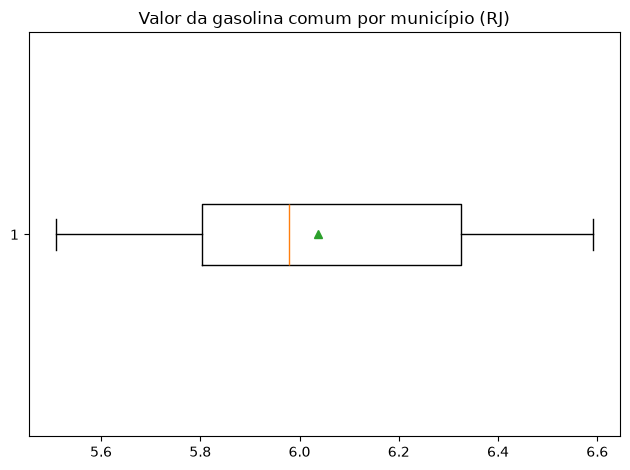

In [421]:
plt.boxplot(array_vlr_venda, orientation='horizontal', showmeans=True)
plt.title('Valor da gasolina comum por município (RJ)')
plt.tight_layout()

#### Nº 4
    Comparando estados: Etanol Hidratado

In [119]:
df_RJSP = df.loc[df['Estado - Sigla'].isin(['RJ','SP']) & (df['Produto'] == 'ETANOL')]
df_RJSP.head()

,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
125,SE,RJ,CAMPOS DOS GOYTACAZES,POSTO DE COMBUSTIVEIS CONTORNO DE CAMPOS LTDA,31.212.889/0002-85,AVENIDA NILO PECANHA,614,/822 PATIO,PQ SANTO AMARO,28030-035,ETANOL,01/01/2024,4.39,NaN,R$ / litro,VIBRA
128,SE,RJ,CAMPOS DOS GOYTACAZES,ARARA FLUMINENSE COMERCIO DE COMBUSTIVEIS LTDA.,07.614.346/0004-71,AVENIDA ALBERTO TORRES,100,NaN,CENTRO,28010-117,ETANOL,01/01/2024,4.29,NaN,R$ / litro,RAIZEN
135,SE,RJ,CAMPOS DOS GOYTACAZES,MOTO MERCANTIL CAMPISTA S A,28.935.153/0001-40,RUA DOS GOYTACAZES,342,NaN,CENTRO,28010-460,ETANOL,01/01/2024,4.29,NaN,R$ / litro,VIBRA
138,SE,RJ,CAMPOS DOS GOYTACAZES,G.S. NOGUEIRA COMBUSTÍVEIS LTDA,03.784.646/0001-03,RUA JOAQUIM LORENA,6,NaN,URURAÍ,28020-230,ETANOL,01/01/2024,4.09,NaN,R$ / litro,BRANCA
143,SE,RJ,CAMPOS DOS GOYTACAZES,CAMPOS GAROUPA LTDA.,03.581.079/0002-60,AVENIDA 15 DE NOVEMBRO,353,NaN,CENTRO,28030-002,ETANOL,01/01/2024,4.17,NaN,R$ / litro,BRANCA


In [ ]:


#df_rj_etanol = df.loc[(df['Estado - Sigla'] == 'RJ') & (df['Produto'] == 'ETANOL')]
#df_sp_etanol = df.loc[(df['Estado - Sigla'] == 'SP') & (df['Produto'] == 'ETANOL')]
#descartado para montar uma tabela com tudo (abaixo)


In [ ]:
df_etanol = df_RJSP.groupby(['Estado - Sigla','Municipio'])['Valor de Venda'].mean().reset_index().sort_values(by = 'Valor de Venda', ascending = False )
df_etanol

,Estado - Sigla,Municipio,Valor de Venda
29,RJ,TRES RIOS,5.128235
18,RJ,PETROPOLIS,5.062155
0,RJ,ANGRA DOS REIS,5.005747
11,RJ,MACAE,4.773617
2,RJ,BARRA DO PIRAI,4.752474
...,...,...,...
58,SP,DRACENA,3.420116
124,SP,SAO ROQUE,3.396087
113,SP,SANTA BARBARA D'OESTE,3.373045
90,SP,MIRASSOL,3.194895


In [333]:
df_etanol_estado = df_RJSP.groupby(['Estado - Sigla'], as_index = False)['Valor de Venda'].mean().sort_values(by = 'Valor de Venda', ascending = False )
#df_etanol_estado

In [353]:
df_rj_etanol_media = (
    df_etanol[df_etanol['Estado - Sigla'] == 'RJ'].groupby(['Estado - Sigla','Municipio'])
    ['Valor de Venda'].mean().reset_index()
    .sort_values(by = 'Valor de Venda', ascending = False )
    )

array_rj_etanol_media = np.array(df_rj_etanol_media['Valor de Venda'])

q1_rj_etanol_media  = np.percentile(array_rj_etanol_media,25)
q3_rj_etanol_media  = np.percentile(array_rj_etanol_media,75)

media_rj = np.mean(array_rj_etanol_media)


iqr_rj_etanol_media  = q3_rj_etanol_media  - q1_rj_etanol_media  

limite_superior_rj_etanol_media  = q3_rj_etanol_media  + (1.5 * iqr_rj_etanol_media )
limite_inferior_rj_etanol_media  = q1_rj_etanol_media  - (1.5 * iqr_rj_etanol_media )

texto_rj_etanol = (
    f'Q1: {q1_rj_etanol_media}\n'
    f'Q3: {q3_rj_etanol_media}\n'

    f'IQR: {iqr_rj_etanol_media}\n' 

    f'\nMédia: {media_rj}\n'  

    f'\nLimite Superior: {limite_superior_rj_etanol_media}\n'
    f'Limite Inferior:   {limite_inferior_rj_etanol_media}'
    )

#print(texto_rj_etanol)

In [351]:
'''df_sp_etanol_media = (
    df_etanol[df_etanol['Estado - Sigla'] == 'SP'].groupby('Municipio')
    ['Valor de Venda'].mean().reset_index()
    .sort_values(by = 'Valor de Venda', ascending = False )
    )'''


df_sp_etanol_media = (
    df_etanol[df_etanol['Estado - Sigla'] == 'SP'].groupby(['Estado - Sigla','Municipio'])
    ['Valor de Venda'].mean().reset_index()
    .sort_values(by = 'Valor de Venda', ascending = False )
    )
 

array_sp_etanol_media = np.array(df_sp_etanol_media['Valor de Venda'])

q1_sp_etanol_media  = np.percentile(array_sp_etanol_media,25)
q3_sp_etanol_media  = np.percentile(array_sp_etanol_media,75)


media_sp = np.mean(array_sp_etanol_media)

iqr_sp_etanol_media  = q3_sp_etanol_media  - q1_sp_etanol_media  

limite_superior_sp_etanol_media  = q3_sp_etanol_media  + (1.5 * iqr_sp_etanol_media )
limite_inferior_sp_etanol_media  = q1_sp_etanol_media  - (1.5 * iqr_sp_etanol_media )

texto_sp_etanol = (
    f'Q1: {q1_sp_etanol_media}\n'
    f'Q3: {q3_sp_etanol_media}\n'

    f'IQR: {iqr_sp_etanol_media}\n'

    f'\nMédia: {media_sp}\n'

    f'\nLimite Superior: {limite_superior_sp_etanol_media}\n'
    f'Limite Inferior:   {limite_inferior_sp_etanol_media}'
    )

#print(texto_sp_etanol)

In [330]:
print(media_rj)
print(media_sp)

4.446460031915704
3.857237583625291


In [331]:
df_etanol_estado = df_RJSP.groupby(['Estado - Sigla'], as_index = False)['Valor de Venda'].mean().sort_values(by = 'Valor de Venda', ascending = False )
df_etanol_estado

,Estado - Sigla,Valor de Venda
0,RJ,4.434487
1,SP,3.896279


#### Gráfico nº 4.1

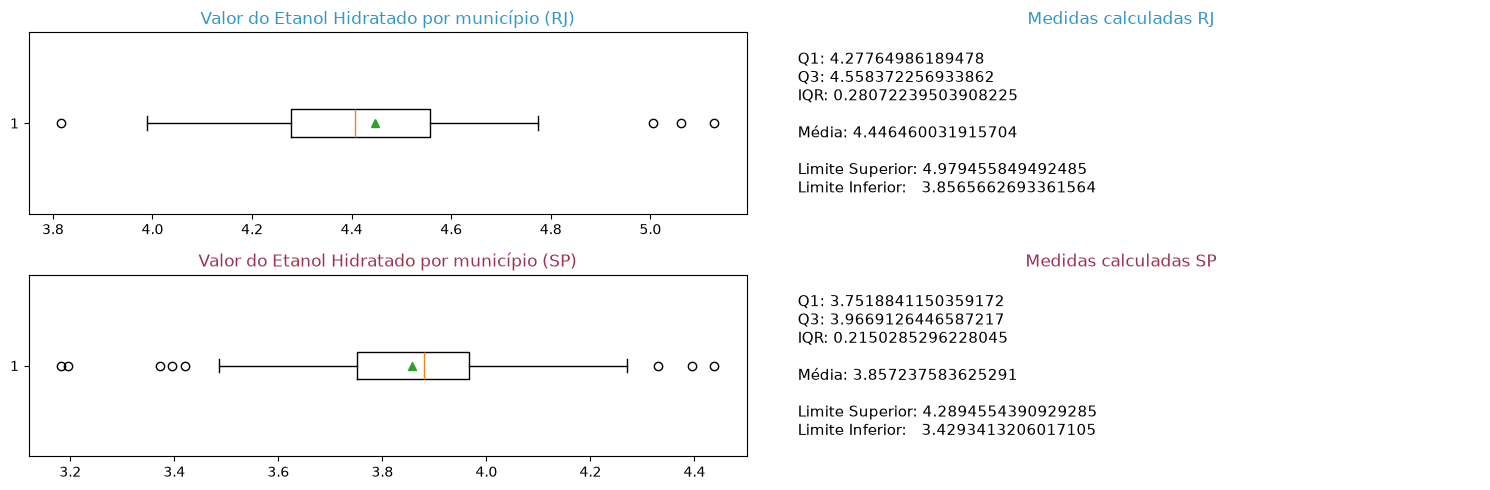

In [412]:
fig, axes = plt.subplots(2,2, figsize=(15,5))
axes[0,0].boxplot(array_rj_etanol_media, orientation='horizontal', showmeans=True)
axes[0,0].set_title('Valor do Etanol Hidratado por município (RJ)', color = '#3297c9')
axes[0,1].axis('off')
axes[0,1].text(0.05, 0.9, texto_rj_etanol, va='top', fontsize=11)
axes[0,1].set_title('Medidas calculadas RJ', color = '#3297c9')
axes[1,0].boxplot(array_sp_etanol_media, orientation='horizontal', showmeans=True)
axes[1,0].set_title('Valor do Etanol Hidratado por município (SP)', color ='#9c324e')
axes[1,1].axis('off')
axes[1,1].text(0.05, 0.9, texto_sp_etanol, va='top', fontsize=11)
axes[1,1].set_title('Medidas calculadas SP', color='#9c324e')
plt.tight_layout()


#### 4.2

In [418]:
limite_sup_etanol_rj = df_rj_etanol_media.loc[df_rj_etanol_media['Valor de Venda'] > limite_superior_rj_etanol_media]
limite_inf_etanol_rj = df_rj_etanol_media.loc[df_rj_etanol_media['Valor de Venda'] < limite_inferior_rj_etanol_media]

limite_sup_etanol_sp = df_sp_etanol_media.loc[df_sp_etanol_media['Valor de Venda'] > limite_superior_sp_etanol_media]
limite_inf_etanol_sp = df_sp_etanol_media.loc[df_sp_etanol_media['Valor de Venda'] < limite_inferior_sp_etanol_media]

#usar matplotlib

outliers_inf_etanol = pd.concat([ 
     limite_inf_etanol_rj,
     limite_inf_etanol_sp 
     ], ignore_index=True)

outliers_sup_etanol = pd.concat([
     limite_sup_etanol_rj,
     limite_sup_etanol_sp,
     ], ignore_index=True)

array_etanol_outliers_inf_municip = np.array(outliers_inf_etanol['Municipio'])
array_etanol_outliers_inf_vlr = np.array(outliers_inf_etanol['Valor de Venda'])

array_etanol_outliers_sup_municip = np.array(outliers_sup_etanol['Municipio'])
array_etanol_outliers_sup_vlr = np.array(outliers_sup_etanol['Valor de Venda'])


#### Gráfico nº4.2

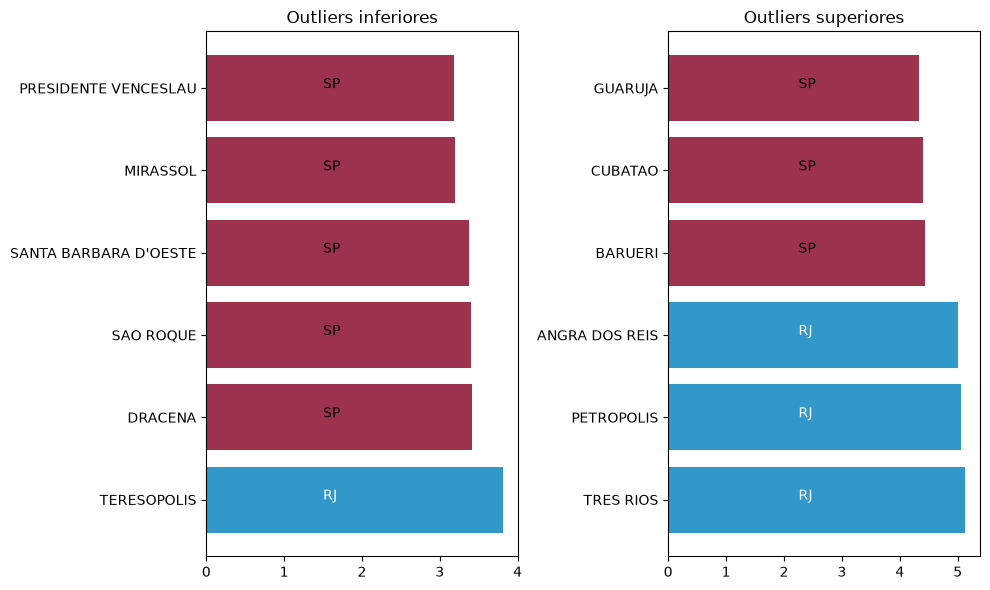

In [419]:




fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].barh(array_etanol_outliers_inf_municip, array_etanol_outliers_inf_vlr, color= ( '#3297c9','#9c324e','#9c324e','#9c324e','#9c324e','#9c324e'))
axes[0].text(1.5, 5, 'SP', color='black')
axes[0].text(1.5, 4, 'SP', color='black')
axes[0].text(1.5, 3, 'SP', color='black')
axes[0].text(1.5, 2, 'SP', color='black')
axes[0].text(1.5, 1, 'SP', color='black')
axes[0].text(1.5, 0, 'RJ', color='white')
axes[0].set_title('Outliers inferiores')
axes[1].barh(array_etanol_outliers_sup_municip, array_etanol_outliers_sup_vlr, color= ( '#3297c9','#3297c9','#3297c9','#9c324e','#9c324e','#9c324e'))
axes[1].text(2.25, 5, 'SP', color='black')
axes[1].text(2.25, 4, 'SP', color='black')
axes[1].text(2.25, 3, 'SP', color='black')
axes[1].text(2.25, 2, 'RJ', color='white')
axes[1].text(2.25, 1, 'RJ', color='white')
axes[1].text(2.25, 0, 'RJ', color='white')
axes[1].set_title('Outliers superiores')
plt.tight_layout()




#### Nº 5
    Bairros da capital: preços dentro ou fora do padrão?

In [172]:
df_rio_gasocomum = df.loc[(df['Municipio'] == 'RIO DE JANEIRO') & (df['Produto'] == 'GASOLINA')]
#df_rio_gasocomum

In [ ]:
df_rio_gasocomum_media = df_rio_gasocomum.groupby('Bairro', as_index=False)['Valor de Venda'].mean().sort_values(by='Valor de Venda', ascending=False)
#df_rio_gasocomum_media

In [400]:
array_rio_vlr_venda = np.array(df_rio_gasocomum_media['Valor de Venda'])

q1_rio_vlr_venda  = np.percentile(array_rio_vlr_venda,25)
q3_rio_vlr_venda  = np.percentile(array_rio_vlr_venda,75)

iqr_rio_vlr_venda  = q3_rio_vlr_venda  - q1_rio_vlr_venda  

limite_superior_rio_vlr_venda  = q3_rio_vlr_venda  + (1.5 * iqr_rio_vlr_venda )
limite_inferior_rio_vlr_venda  = q1_rio_vlr_venda  - (1.5 * iqr_rio_vlr_venda )

texto_rio_gasocomum = (f' Q1: {q1_rio_vlr_venda}'
    f'\n Q3: {q3_rio_vlr_venda}'

    f'\n IQR: {iqr_rio_vlr_venda}\n'

    f'\n Limite Superior: {limite_superior_rio_vlr_venda}'
    f'\n Limite Inferior: {limite_inferior_rio_vlr_venda}\n'
    
    f'\n\n\n\n Outlier Superior localizado no bairro Flamengo'
    )




In [183]:
limite_inf_rio_gasocomum = df_rio_gasocomum_media.loc[df_rio_gasocomum_media['Valor de Venda'] < limite_inferior_rio_vlr_venda]
#outliers inferiores inesxistentes

limite_sup_rio_gasocomum = df_rio_gasocomum_media.loc[df_rio_gasocomum_media['Valor de Venda'] > limite_superior_rio_vlr_venda]
limite_sup_rio_gasocomum
#outliers superiores provenientes de bairros nobress

,Bairro,Valor de Venda
23,FLAMENGO,6.696667


#### Gráfico nº 5

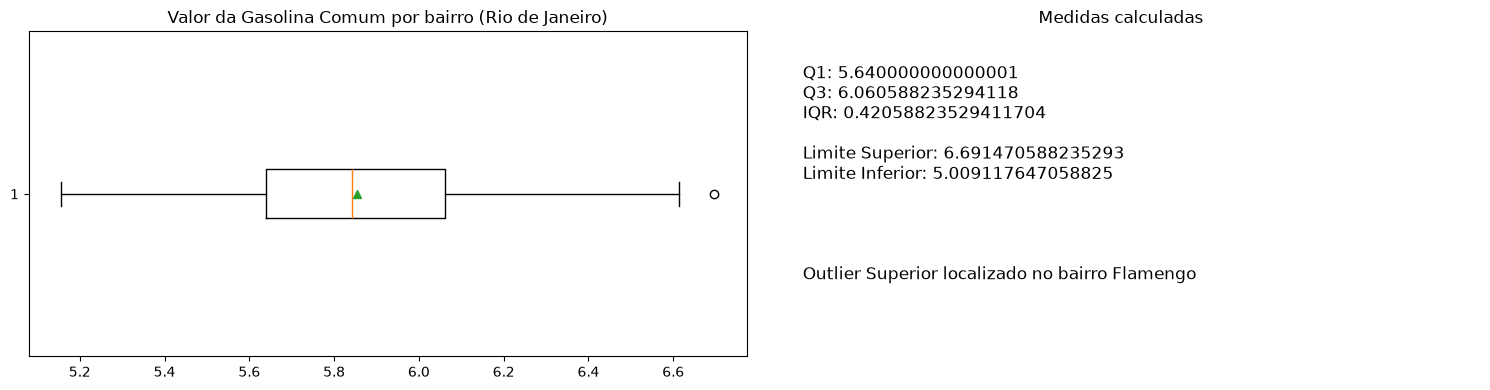

In [420]:

fig, axes = plt.subplots(1,2, figsize=(15,4))
axes[0].boxplot(array_rio_vlr_venda, orientation='horizontal', showmeans=True)
axes[0].set_title('Valor da Gasolina Comum por bairro (Rio de Janeiro)')
axes[1].axis('off')
axes[1].text(0.05, 0.9, texto_rio_gasocomum, va='top', fontsize=12)
axes[1].set_title('Medidas calculadas')
plt.tight_layout()